# Exploratory Data Analysis: Reliance Industries Ltd. (NSE: RELIANCE)

**Objective**
- We study the daily share price of Reliance Industries.
- Reliance is one of India's largest listed companies.
- We look at three things: returns, volatility and trend.
- The aim is to describe the data, not to predict anything.

**Data**
- Source: daily prices from NSE.
- Period: January 2008 to October 2026.
- Size: about 4,640 trading days.
- Prices are adjusted for stock splits and bonus issues.

**Sections**
- 1. Price history
- 2. Daily returns and their distribution
- 3. Rolling volatility
- 4. Trend (moving averages)
- 5. Summary of findings

In [1]:
# ---- Libraries --------------------------------------------------------------
import pandas as pd                          # tables of data (think: Excel inside Python)
import numpy as np                           # fast maths on numbers
from scipy import stats                      # statistics tools: skewness, kurtosis, normal curve
import matplotlib.pyplot as plt              # draws the charts
import matplotlib.dates as mdates            # formats dates on the chart axes

# ---- Chart style ------------------------------------------------------------
plt.rcParams["figure.facecolor"] = "white"   # white chart background
plt.rcParams["axes.grid"] = True             # show grid lines on charts
plt.rcParams["grid.alpha"] = 0.3             # make grid lines faint (30% visible)

# ---- Load the data ----------------------------------------------------------
df = pd.read_csv("data/RELIANCE.csv",                       # read the CSV file into a table
                 usecols=["date", "adj_close", "volume"])   # keep only the 3 columns we need
df["date"] = pd.to_datetime(df["date"])                     # convert date text into real dates
df = df.sort_values("date").reset_index(drop=True)          # oldest day first; rows numbered 0, 1, 2...

# ---- Quick look at the data -------------------------------------------------
print(f"Rows: {len(df)}")                                                     # number of trading days
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")  # first and last date
df.head()                                                                     # show the first 5 rows

Rows: 4644
Date range: 2008-01-01 to 2026-10-28


,date,volume,adj_close
0,2008-01-01,10540548,284.750061
1,2008-01-02,27276294,286.099762
2,2008-01-03,30204199,290.293640
3,2008-01-04,35463186,299.221313
4,2008-01-07,27412209,301.945679


## 1. Price history

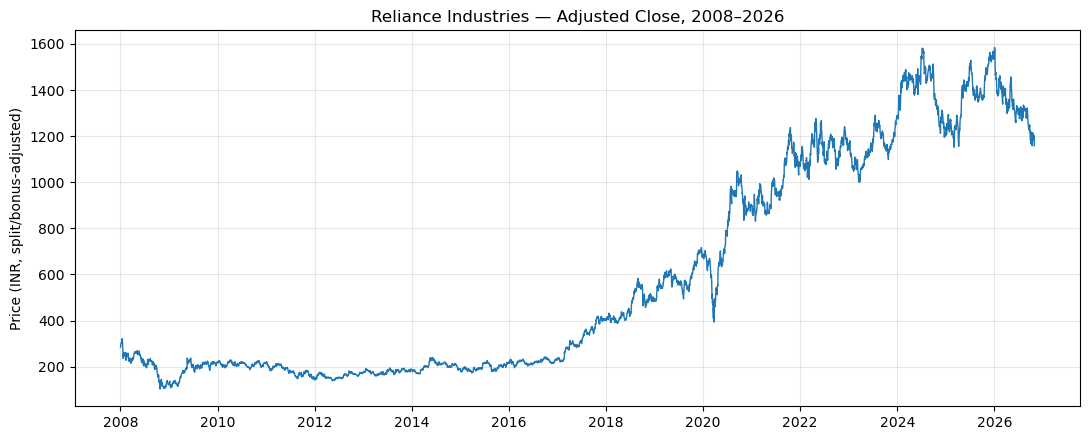

Price, 2008-01-01: 284.8
Price, 2026-10-28: 1158.0
CAGR over the full period: 7.7% per year


In [2]:
# ---- Draw the price chart ---------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.5))                  # create an empty chart, 11 x 4.5 inches
ax.plot(df["date"], df["adj_close"],                       # x-axis: date, y-axis: closing price
        color="#1f77b4", linewidth=1)                      # thin blue line
ax.set_title("Reliance Industries — Adjusted Close, 2008–2026")        # chart title
ax.set_ylabel("Price (INR, split/bonus-adjusted)")                     # label for the y-axis
ax.xaxis.set_major_locator(mdates.YearLocator(2))          # place a date label every 2 years
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))   # show just the year, e.g. 2010
plt.tight_layout()                                         # stop labels getting cut off
plt.savefig("price_history.png", dpi=110)                  # save the chart as an image file
plt.show()                                                 # display the chart below

# ---- Compound annual growth rate (CAGR) -------------------------------------
start_price = df["adj_close"].iloc[0]                      # the very first price in the data
end_price = df["adj_close"].iloc[-1]                       # the very last price in the data
years = (df["date"].iloc[-1] - df["date"].iloc[0]).days / 365.25   # total years covered
cagr = (end_price / start_price) ** (1 / years) - 1        # steady yearly growth that turns start into end
print(f"Price, {df['date'].iloc[0].date()}: {start_price:.1f}")        # print the starting price
print(f"Price, {df['date'].iloc[-1].date()}: {end_price:.1f}")         # print the ending price
print(f"CAGR over the full period: {cagr * 100:.1f}% per year")        # print growth rate as a percentage

**What we see**
- The price rose from about 285 to about 1,158 over the period.
- That is growth of about 7.7% per year (CAGR).
- The price trends up over time, so its average keeps changing.
- This makes raw prices hard to compare across years.
- So the next sections study daily returns instead of prices.

## 2. Daily returns and their distribution

In [3]:
# ---- Daily returns ------------------------------------------------------------
df["return"] = df["adj_close"].pct_change()      # % change from the previous day's price
returns = df["return"].dropna()                  # drop the first row (it has no previous day)

# ---- Summary statistics -----------------------------------------------------
mean_daily = returns.mean()                      # average daily return
std_daily = returns.std()                        # daily volatility (how much returns vary)
skew = stats.skew(returns)                       # skewness: are big moves lopsided up or down?
kurt = stats.kurtosis(returns)                   # excess kurtosis: how fat are the tails? (0 = normal)

# ---- Print the results ------------------------------------------------------
print(f"Mean daily return:        {mean_daily*100:.4f}%  ({mean_daily*252*100:.2f}% annualized)")           # x252 trading days = yearly
print(f"Daily volatility (std):   {std_daily*100:.4f}%  ({std_daily*np.sqrt(252)*100:.2f}% annualized)")    # x sqrt(252) = yearly
print(f"Skewness:                 {skew:+.3f}")                                  # + means longer right tail
print(f"Excess kurtosis:          {kurt:+.3f}  (0 = normal distribution)")      # above 0 means fatter tails
print(f"Worst single day:         {returns.min()*100:.2f}%  on {df.loc[returns.idxmin(), 'date'].date()}")   # biggest fall and its date
print(f"Best single day:          {returns.max()*100:.2f}%  on {df.loc[returns.idxmax(), 'date'].date()}")   # biggest rise and its date

Mean daily return:        0.0493%  (12.43% annualized)
Daily volatility (std):   1.9563%  (31.06% annualized)
Skewness:                 +0.279
Excess kurtosis:          +9.295  (0 = normal distribution)
Worst single day:         -16.27%  on 2008-10-24
Best single day:          21.37%  on 2009-05-18


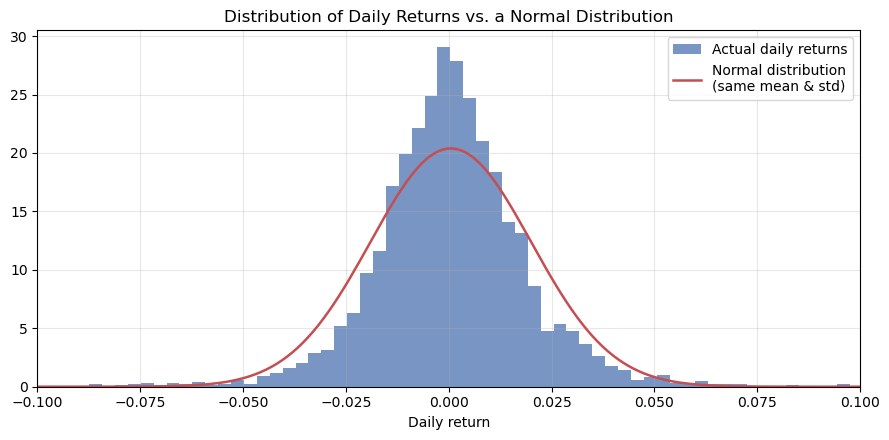

In [4]:
# ---- Histogram of daily returns vs. a normal curve --------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))                   # create an empty chart, 9 x 4.5 inches
ax.hist(returns, bins=120, density=True,                   # bar chart of returns, 120 bars, scaled to area = 1
        alpha=0.75, color="#4c72b0",                       # slightly see-through blue bars
        label="Actual daily returns")                      # legend text for the bars

x = np.linspace(returns.min(), returns.max(), 300)         # 300 evenly spaced points across the return range
normal_curve = stats.norm.pdf(x, mean_daily, std_daily)    # height of a normal curve at each point (same mean & std)
ax.plot(x, normal_curve, color="#c44e52", linewidth=1.8,   # draw that normal curve in red
        label="Normal distribution\n(same mean & std)")    # legend text for the red line

ax.set_xlim(-0.10, 0.10)                                   # zoom in: show returns between -10% and +10%
ax.set_title("Distribution of Daily Returns vs. a Normal Distribution")   # chart title
ax.set_xlabel("Daily return")                              # label for the x-axis
ax.legend()                                                # show the legend box
plt.tight_layout()                                         # stop labels getting cut off
plt.savefig("return_distribution.png", dpi=110)            # save the chart as an image file
plt.show()                                                 # display the chart below

**What we see**
- The average daily return is small: about 0.05% a day.
- Added up over a year, the simple average is about 12.4%.
- The compounded growth is lower, at 7.7% a year.
- The gap exists because ups and downs reduce compounded growth.
- Daily volatility is about 1.96%, or about 31% a year.

**Skewness (+0.28)**
- Skewness shows whether big moves lean up or down.
- The value is slightly positive, so big up days are a little larger.
- One day drives much of this: +21.4% on 2009-05-18.
- That was the day of the 2009 Indian election result.
- The market rallied hard, and trading was briefly halted.
- One extreme day can change skewness a lot.

**Kurtosis (+9.3)**
- Kurtosis shows how often extreme days happen.
- A normal distribution scores 0. Reliance scores about 9.3.
- So extreme days happen far more often than a normal curve predicts.
- In the chart, the blue bars are taller in the middle than the red curve.
- The blue bars also have more outliers in the tails.

**Why it matters**
- Risk tools that assume a normal curve understate the chance of big moves.
- Tail-aware measures such as historical VaR are safer to use.

## 3. Rolling volatility

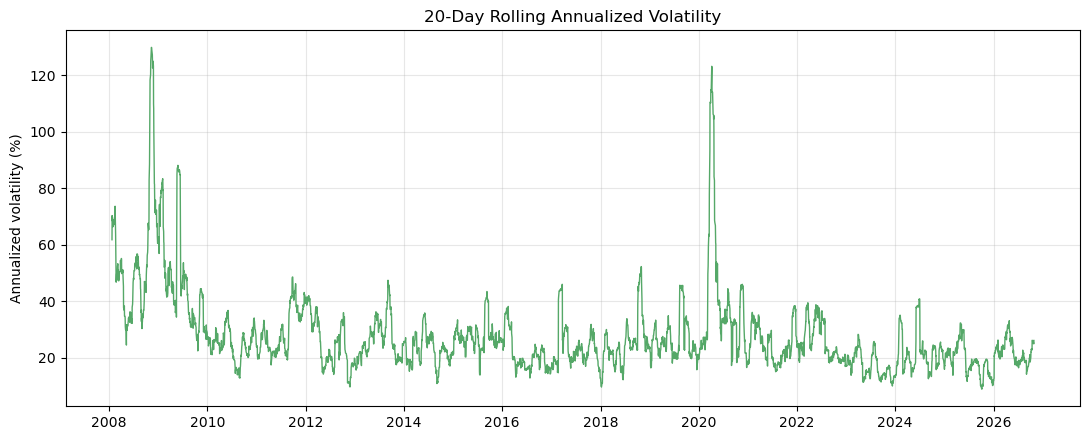

Median annualized volatility: 23.9%
90th percentile:              42.1%
Highest reading:              129.9%  around 2008-11-10


In [5]:
# ---- Rolling volatility -------------------------------------------------------
df["volatility_20d"] = (df["return"].rolling(20, min_periods=15).std()   # std of the last 20 days (needs at least 15)
                        * np.sqrt(252))                                  # scale to a yearly figure

# ---- Draw the volatility chart ----------------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.5))                  # create an empty chart, 11 x 4.5 inches
ax.plot(df["date"], df["volatility_20d"] * 100,            # x-axis: date, y-axis: volatility in %
        color="#55a868", linewidth=1)                      # thin green line
ax.set_title("20-Day Rolling Annualized Volatility")       # chart title
ax.set_ylabel("Annualized volatility (%)")                 # label for the y-axis
ax.xaxis.set_major_locator(mdates.YearLocator(2))          # place a date label every 2 years
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))   # show just the year
plt.tight_layout()                                         # stop labels getting cut off
plt.savefig("rolling_volatility.png", dpi=110)             # save the chart as an image file
plt.show()                                                 # display the chart below

# ---- Print key volatility levels --------------------------------------------
print(f"Median annualized volatility: {df['volatility_20d'].median()*100:.1f}%")     # the "typical" level
print(f"90th percentile:              {df['volatility_20d'].quantile(0.9)*100:.1f}%")   # only 10% of days were more volatile
print(f"Highest reading:              {df['volatility_20d'].max()*100:.1f}%  "           # the peak value...
      f"around {df.loc[df['volatility_20d'].idxmax(), 'date'].date()}")                  # ...and when it happened

**What we see**
- Volatility is not constant. It changes over time.
- Typical volatility is about 24% a year.
- On the most volatile 10% of days, it was above 42%.
- The highest reading was about 130%, in November 2008.
- That was the global financial crisis.
- Another sharp spike came in March 2020, during the COVID selloff.
- After each spike, volatility fell back over weeks or months.

**Volatility clustering**
- Calm periods tend to follow calm periods.
- Turbulent periods tend to follow turbulent periods.
- This pattern is common in financial data.
- Models such as GARCH are built to capture it.

## 4. Trend: price versus moving averages

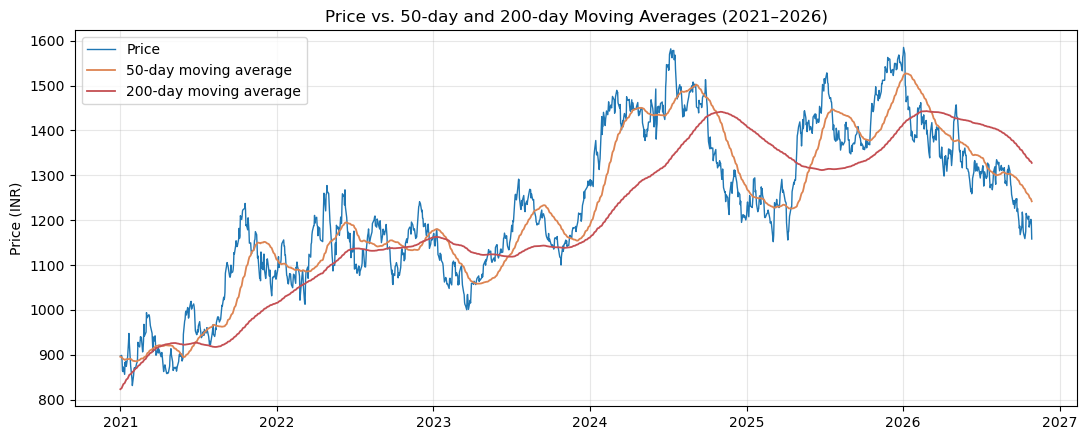

In [6]:
# ---- Moving averages --------------------------------------------------------
df["ma_50"] = df["adj_close"].rolling(50).mean()           # average price of the last 50 days
df["ma_200"] = df["adj_close"].rolling(200).mean()         # average price of the last 200 days

recent = df[df["date"] >= "2021-01-01"]                    # keep only 2021 onwards so the chart is easier to read

# ---- Draw the trend chart ---------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.5))                  # create an empty chart, 11 x 4.5 inches
ax.plot(recent["date"], recent["adj_close"],               # daily price
        color="#1f77b4", linewidth=1, label="Price")                       # thin blue line
ax.plot(recent["date"], recent["ma_50"],                   # 50-day average (reacts faster)
        color="#dd8452", linewidth=1.3, label="50-day moving average")     # orange line
ax.plot(recent["date"], recent["ma_200"],                  # 200-day average (reacts slower)
        color="#c44e52", linewidth=1.3, label="200-day moving average")    # red line
ax.set_title("Price vs. 50-day and 200-day Moving Averages (2021–2026)")   # chart title
ax.set_ylabel("Price (INR)")                               # label for the y-axis
ax.legend()                                                # show the legend box
plt.tight_layout()                                         # stop labels getting cut off
plt.savefig("moving_averages.png", dpi=110)                # save the chart as an image file
plt.show()                                                 # display the chart below

**What we see**
- A moving average smooths out daily noise.
- The 50-day average reacts faster than the 200-day average.
- The 200-day average is a slow guide to the long-term trend.
- When the price stays above it, the trend is usually up.
- When the price stays below it, the trend is usually down.
- A "golden cross" is when the 50-day crosses above the 200-day.
- A "death cross" is when the 50-day crosses below the 200-day.

**Limitation**
- Moving averages use past prices only.
- So they always turn after the price has already turned.

## 5. Summary of findings

**Key findings**
- **Growth:** the price grew about 7.7% a year from 2008 to 2026.
- **Returns:** the average daily return is small and positive.
- **Skewness:** slightly positive (+0.28), driven by one huge day in 2009.
- **Kurtosis:** high (+9.3). Extreme days happen more often than a normal curve predicts.
- **Volatility:** it changes over time. It spiked in 2008 and 2020.
- **Trend:** the 200-day average shows the long-term direction, but it lags.

**What this means**
- Do not assume returns follow a normal curve.
- Do not assume volatility stays constant.
- Both assumptions are wrong for this stock.

**Next step**
- Pick one clear idea, such as a trend or volatility rule.
- Fix a test period in advance.
- Check if the idea still works in that period.